In [1]:
import numpy as np
import pandas as pd
import xarray as xr 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

In [2]:
plotdir = "/home/kperny/VolMIP_stratosphere/plots/PAPER/"
piControl = pd.read_csv("/home/kperny/VolMIP_stratosphere/tab/diagnostics_piControl.csv")
nam_flags = pd.read_csv("/home/kperny/VolMIP_stratosphere/tab/nam_flags.csv")
models = nam_flags['model'].unique()

piControl[nam_flags.columns[1:]] = nam_flags[nam_flags.columns[1:]]

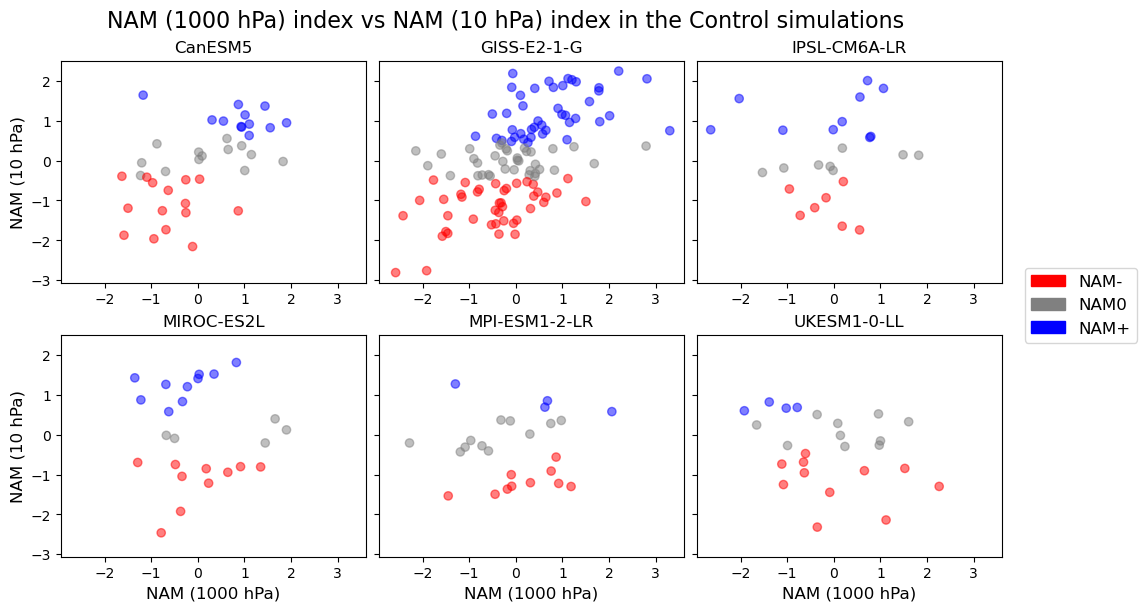

In [5]:
fig, axs = plt.subplots(2,3, figsize=(10,6), sharey=True, sharex=True, layout='constrained')

data = piControl.set_index(['model','realization'])
for ax, model in zip(axs.flat, models):
    tmp = data.loc[model]
    ax.scatter(tmp['nam_1000_pi'], tmp['nam_10_pi'], c=tmp['flag_10_pi'].map({-1: 'red', 0: 'grey', 1: 'blue'}), alpha=0.5)
    ax.set_title(model, fontsize=12)
#axs[-1,-1].set_axis_off()
fig.suptitle('NAM (1000 hPa) index vs NAM (10 hPa) index in the Control simulations', fontsize=16)
axs[0,0].set_ylabel('NAM (10 hPa)', fontsize=12)
axs[1,0].set_ylabel('NAM (10 hPa)', fontsize=12)
axs[1,0].set_xlabel('NAM (1000 hPa)', fontsize=12)
axs[1,1].set_xlabel('NAM (1000 hPa)', fontsize=12)
axs[1,2].set_xlabel('NAM (1000 hPa)', fontsize=12)
axs[0,2].xaxis.set_tick_params(labelbottom=True)
axs[0,1].xaxis.set_tick_params(labelbottom=True)
axs[0,0].xaxis.set_tick_params(labelbottom=True)

# legend
import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='blue', label='NAM+')
green_patch = mpatches.Patch(color='grey', label='NAM0')
red_patch = mpatches.Patch(color='red', label='NAM-')

fig.legend(handles=[red_patch, green_patch, blue_patch], loc='center', ncol=1, fontsize=12, bbox_to_anchor=(1.075,0.5))


plt.savefig(plotdir + 'supp_nam.png', dpi=200, bbox_inches='tight')